# Duka Electronics H1 2026 Board Report

## Storyboard

- **Audience:** Duka Electronics board members
- **Decision:** Where to focus sales, branch support and inventory resources in H2 2026
- **Big Idea:** Nairobi leads overall, but weaker Mombasa and Nakuru performance in Q2 creates a focused recovery opportunity
- **SCR:** **Situation** - H1 sales are concentrated in Nairobi and In-store channels. **Complication** - Mombasa and Nakuru weaken in Q2. **Resolution** - Target recovery support to weak branches while sustaining the strongest products and channels.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
for folder in ['figures','reports','dashboard_images']:
    Path(folder).mkdir(exist_ok=True)
plt.style.use('default')

In [2]:
sales = pd.read_csv('duka_sales.csv', parse_dates=['order_date'])
sales['revenue'] = sales['quantity'] * sales['unit_price']
sales['month'] = sales['order_date'].dt.to_period('M')
sales['quarter'] = np.where(sales['order_date'].dt.month <= 3, 'Q1', 'Q2')
sales['month_label'] = sales['order_date'].dt.strftime('%b')
print(sales.shape)
sales.head()

(1000, 11)


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,quarter,month_label
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000,2026-06,Q2,Jun
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000,2026-02,Q1,Feb
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000,2026-01,Q1,Jan
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500,2026-04,Q2,Apr
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500,2026-03,Q1,Mar


In [3]:
branch_rev = sales.groupby('branch')['revenue'].sum().sort_values() / 1_000_000
monthly_rev = sales.groupby('month')['revenue'].sum() / 1_000_000
chan_rev = sales.groupby('channel')['revenue'].sum().sort_values() / 1_000_000
q_piv = sales.pivot_table(index='branch', columns='quarter', values='revenue', aggfunc='sum') / 1_000_000
print('Branch revenue (KES m):')
display(branch_rev.to_frame())
print('Quarterly branch revenue (KES m):')
display(q_piv.round(2))

Branch revenue (KES m):


,revenue
branch,
Eldoret,8.8442
Kisumu,10.8681
Nakuru,11.9704
Mombasa,14.0037
Nairobi,26.1061


Quarterly branch revenue (KES m):


quarter,Q1,Q2
branch,,
Eldoret,3.54,5.31
Kisumu,5.01,5.86
Mombasa,8.02,5.98
Nairobi,12.48,13.62
Nakuru,6.90,5.07


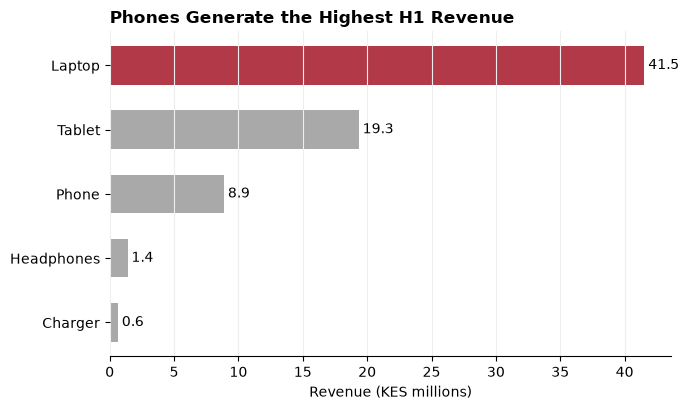

In [4]:
prod_rev = sales.groupby('product')['revenue'].sum().sort_values() / 1_000_000
top_product = prod_rev.idxmax()
colors = ['#B23A48' if p == top_product else '#A9A9A9' for p in prod_rev.index]
fig, ax = plt.subplots(figsize=(7,4.2))
bars=ax.barh(prod_rev.index, prod_rev.values, color=colors, height=.6)
ax.set_title('Phones Generate the Highest H1 Revenue', loc='left', fontweight='bold')
ax.set_xlabel('Revenue (KES millions)')
ax.grid(axis='x', color='#EEEEEE')
ax.spines[['top','right','left']].set_visible(False)
for b,v in zip(bars,prod_rev.values): ax.text(v+.3,b.get_y()+b.get_height()/2,f'{v:.1f}',va='center')
plt.tight_layout()
plt.savefig('figures/before.png',dpi=180,bbox_inches='tight')
plt.show()

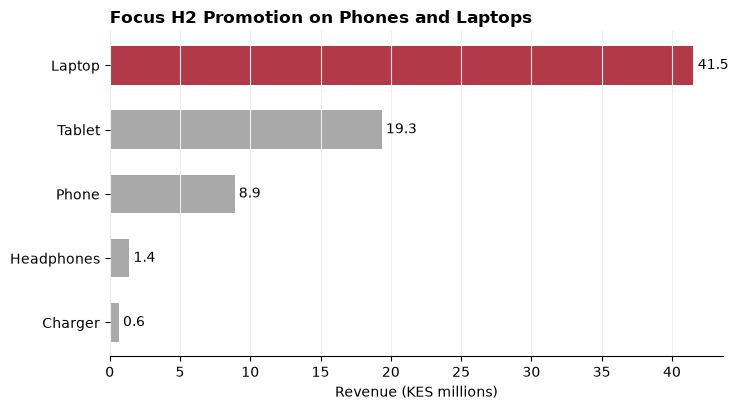

In [5]:
fig, ax = plt.subplots(figsize=(7.5,4.2))
bars=ax.barh(prod_rev.index, prod_rev.values, color=colors, height=.6)
ax.set_title('Focus H2 Promotion on Phones and Laptops', loc='left', fontweight='bold')
ax.set_xlabel('Revenue (KES millions)')
ax.grid(axis='x', color='#EEEEEE')
ax.spines[['top','right','left']].set_visible(False)
for b,v in zip(bars,prod_rev.values): ax.text(v+.3,b.get_y()+b.get_height()/2,f'{v:.1f}',va='center')
plt.tight_layout()
plt.savefig('figures/after.png',dpi=180,bbox_inches='tight')
plt.show()

## Before-and-After: Design Changes

1. **Vertical bars became horizontal bars:** product names are easier to read.
2. **Noisy grey was replaced by a single highlighted top product:** attention now goes to the priority category.
3. **The axis and grid became more readable:** units are explicit and the source is clear.
4. **The title changed from a category label to an insight statement:** it communicates the H2 decision.

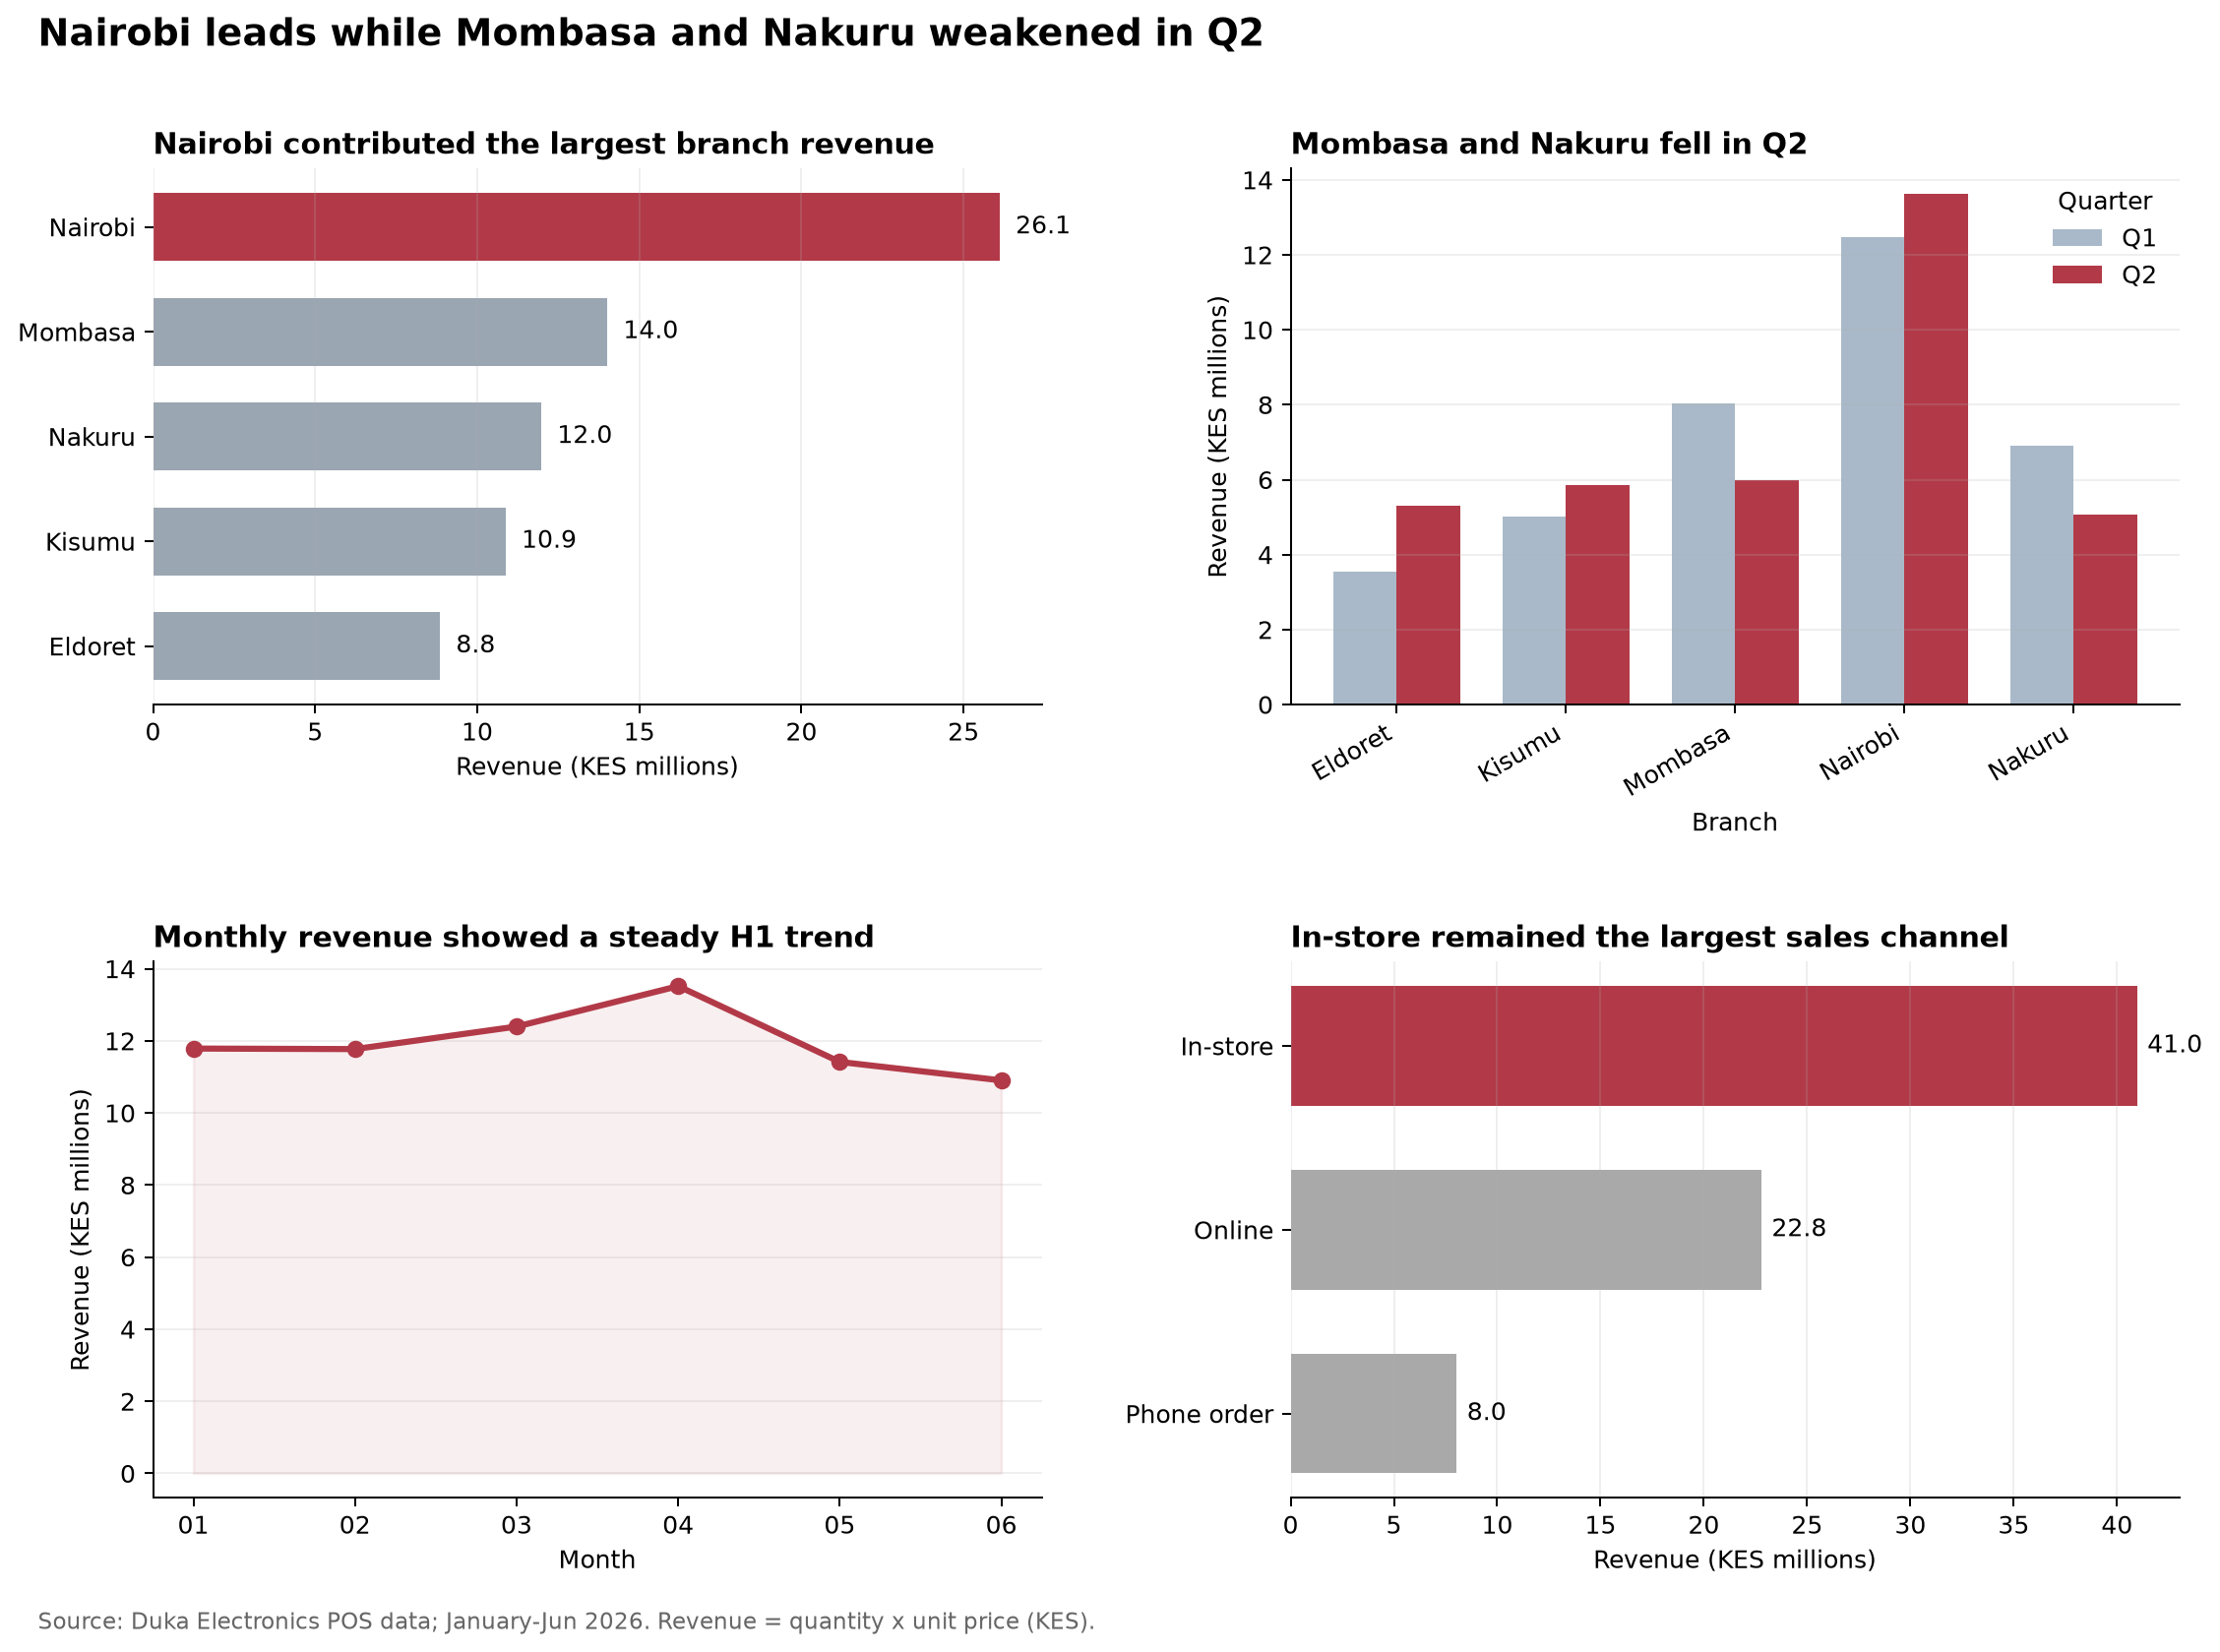

In [6]:
fig, axes = plt.subplots(2,2,figsize=(13,9.5),dpi=180)
fig.patch.set_facecolor('white')
fig.suptitle('Nairobi leads while Mombasa and Nakuru weakened in Q2',fontsize=15,fontweight='bold',x=.04,y=.97,ha='left')

ax=axes[0,0]
colors_b=['#B23A48' if b=='Nairobi' else '#9AA6B2' for b in branch_rev.index]
ax.barh(branch_rev.index,branch_rev.values,color=colors_b,height=.65)
ax.set_title('Nairobi contributed the largest branch revenue',loc='left',fontweight='bold')
ax.set_xlabel('Revenue (KES millions)')
ax.spines[['top','right','left']].set_visible(False); ax.grid(axis='x',alpha=.2)
for i,v in enumerate(branch_rev.values): ax.text(v+.5,i,f'{v:.1f}',va='center')

ax=axes[0,1]
q_piv.plot(kind='bar',ax=ax,color=['#A9B9C9','#B23A48'],width=.75)
ax.set_title('Mombasa and Nakuru fell in Q2',loc='left',fontweight='bold')
ax.set_xlabel('Branch'); ax.set_ylabel('Revenue (KES millions)')
ax.legend(title='Quarter',frameon=False); ax.spines[['top','right']].set_visible(False); ax.grid(axis='y',alpha=.2)
plt.setp(ax.get_xticklabels(),rotation=30,ha='right')

ax=axes[1,0]
ax.plot([str(x).replace('2026-','') for x in monthly_rev.index],monthly_rev.values,color='#B23A48',marker='o',linewidth=2.5)
ax.fill_between(range(len(monthly_rev)),monthly_rev.values,alpha=.08,color='#B23A48')
ax.set_title('Monthly revenue showed a steady H1 trend',loc='left',fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Revenue (KES millions)')
ax.spines[['top','right']].set_visible(False); ax.grid(axis='y',alpha=.2)

ax=axes[1,1]
chan_colors=['#B23A48' if c=='In-store' else '#A9A9A9' for c in chan_rev.index]
ax.barh(chan_rev.index,chan_rev.values,color=chan_colors,height=.65)
ax.set_title('In-store remained the largest sales channel',loc='left',fontweight='bold')
ax.set_xlabel('Revenue (KES millions)')
ax.spines[['top','right','left']].set_visible(False); ax.grid(axis='x',alpha=.2)
for i,v in enumerate(chan_rev.values): ax.text(v+.5,i,f'{v:.1f}',va='center')

fig.text(.04,.012,'Source: Duka Electronics POS data; January-Jun 2026. Revenue = quantity x unit price (KES).',fontsize=9,color='#666666')
plt.subplots_adjust(left=.09,right=.97,top=.88,bottom=.09,hspace=.48,wspace=.28)
plt.savefig('reports/duka_board_report.png',dpi=220,bbox_inches='tight')
plt.show()

## Recommendations

- Protect Nairobi and In-store momentum while allocating targeted H2 recovery support to Mombasa and Nakuru.
- Prioritise Phones and Laptops for promotions and inventory planning.
- Continue monitoring monthly and branch performance through the Looker Studio dashboard.